#PREPROCESSING


In [25]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder  # one-hot encode
from sklearn.preprocessing import StandardScaler # normalize

from sklearn.neighbors import KNeighborsClassifier # knn
from sklearn.naive_bayes import GaussianNB         # naive bayes (gaussian)
from sklearn.tree import DecisionTreeClassifier    # decision tree

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score) # metrics

from sklearn.metrics import classification_report

from sklearn.metrics import ConfusionMatrixDisplay # error matrix

import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("dataset/ObesityDataSet_raw_and_data_sinthetic.csv")

In [3]:
# Get some information about the dataset

#print("Number of rows:", df.shape[0])
#print("Number of columns:", df.shape[1])

#print("\n")

#df.info()

In [4]:
# Let's check for missing values in the dataset
#print(f"Missing values in the dataset: {df.isnull().sum().sum()}")

#print("\n")

# Let's check for duplicate rows in the dataset
#print(f"Duplicate rows in the dataset: {df.duplicated().sum()}")

# Let's remove duplicate rows
#if(df.duplicated().sum() > 0):
#    df = df.drop_duplicates()

In [5]:
x = df.drop("NObeyesdad", axis=1) # axis=1 == axis='columns'

y = df["NObeyesdad"]

#print(f"Features:\n{x.head()}")
#print("\n")
#print(f"Target:\n{y.head()}")


In [6]:
# Let's check the distribution of the target

#print(y.value_counts())
#print(y.value_counts(normalize=True) * 100)

# The biggest class has 16.82% and the smallest class has 12.79%

In [7]:
# Let's check the of some features in the dataset

# SMOKE
df[df["SMOKE"] == "yes"]["NObeyesdad"].value_counts(normalize=True) * 100

NObeyesdad
Obesity_Type_II        34.090909
Normal_Weight          29.545455
Obesity_Type_I         13.636364
Overweight_Level_II    11.363636
Overweight_Level_I      6.818182
Obesity_Type_III        2.272727
Insufficient_Weight     2.272727
Name: proportion, dtype: float64

In [8]:
# Let's separate the features into categorical and numerical

categorical_features = [
                "Gender", 
                "family_history_with_overweight", 
                "FAVC",
                "CAEC",
                "SMOKE",
                "SCC",
                "CALC",
                "MTRANS"
                    ]

numeric_features = [
                "Age",
                "Height",
                "Weight",
                "FCVC",
                "NCP",
                "CH2O",
                "FAF",
                "TUE"
                    ]

In [9]:

# Let's split the dataset into training and testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y) 

In [10]:
# Let's normalize numerical features and decode categorical features

preprocessor = ColumnTransformer(transformers=[
                ("numerical"  , StandardScaler()                      , numeric_features),
                ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
                ])

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

In [11]:
print(x_train_processed.shape)

(1688, 30)


In [12]:
preprocessor.get_feature_names_out()

# ele nao esta por alguma razao pegando certo no one hot encode o CALC_always, tem apenas o CALC_sometimes, CALC_no e CALC_frequently
# por isso que x_train_processed.shape esta dando 30 e nao 31
# mas no print(df["CALC"].unique()) ele mostra que tem 4 possiveis valores, entao nao sei pq nao esta pegando corretamente

array(['numerical__Age', 'numerical__Height', 'numerical__Weight',
       'numerical__FCVC', 'numerical__NCP', 'numerical__CH2O',
       'numerical__FAF', 'numerical__TUE', 'categorical__Gender_Female',
       'categorical__Gender_Male',
       'categorical__family_history_with_overweight_no',
       'categorical__family_history_with_overweight_yes',
       'categorical__FAVC_no', 'categorical__FAVC_yes',
       'categorical__CAEC_Always', 'categorical__CAEC_Frequently',
       'categorical__CAEC_Sometimes', 'categorical__CAEC_no',
       'categorical__SMOKE_no', 'categorical__SMOKE_yes',
       'categorical__SCC_no', 'categorical__SCC_yes',
       'categorical__CALC_Frequently', 'categorical__CALC_Sometimes',
       'categorical__CALC_no', 'categorical__MTRANS_Automobile',
       'categorical__MTRANS_Bike', 'categorical__MTRANS_Motorbike',
       'categorical__MTRANS_Public_Transportation',
       'categorical__MTRANS_Walking'], dtype=object)

In [13]:
print(df["Gender"].unique())
print(df["family_history_with_overweight"].unique())
print(df["FAVC"].unique())
print(df["CAEC"].unique())
print(df["SMOKE"].unique())
print(df["SCC"].unique())
print(df["CALC"].unique())
print(df["MTRANS"].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str
<StringArray>
['yes', 'no']
Length: 2, dtype: str
<StringArray>
['no', 'yes']
Length: 2, dtype: str
<StringArray>
['Sometimes', 'Frequently', 'Always', 'no']
Length: 4, dtype: str
<StringArray>
['no', 'yes']
Length: 2, dtype: str
<StringArray>
['no', 'yes']
Length: 2, dtype: str
<StringArray>
['no', 'Sometimes', 'Frequently', 'Always']
Length: 4, dtype: str
<StringArray>
['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
Length: 5, dtype: str


In [14]:
# Let's declare the models we will use

knn = KNeighborsClassifier(n_neighbors=5)

naive_bayes = GaussianNB()

tree = DecisionTreeClassifier(random_state=42)

In [15]:
# Let's train the models

knn.fit(x_train_processed, y_train)

naive_bayes.fit(x_train_processed, y_train)

tree.fit(x_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [16]:
# Let's evaluate the models

pred_knn = knn.predict(x_test_processed)

pred_naive_bayes = naive_bayes.predict(x_test_processed)

pred_tree = tree.predict(x_test_processed)

In [17]:
# Let's see if the models are predicting it correctly just looking at the first 10 predictions

print("======== KNN ========")
print("Real values:")
print(y_test.head(10).to_list())

print("KNN predictions:")
print(pred_knn[:10].tolist())

print("\n")

print("======== Naive Bayes ========")
print("Real values:")
print(y_test.head(10).to_list())

print("Naive Bayes predictions:")
print(pred_naive_bayes[:10].tolist())

print("\n")

print("======== Decision Tree ========")
print("Real values:")
print(y_test.head(10).to_list())

print("Decision Tree predictions:")
print(pred_tree[:10].tolist())

======== KNN ========
Real values:
['Overweight_Level_I', 'Overweight_Level_I', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_II', 'Overweight_Level_I', 'Insufficient_Weight', 'Obesity_Type_III', 'Obesity_Type_III', 'Insufficient_Weight']
KNN predictions:
['Overweight_Level_II', 'Overweight_Level_I', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_II', 'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_III', 'Obesity_Type_III', 'Insufficient_Weight']


======== Naive Bayes ========
Real values:
['Overweight_Level_I', 'Overweight_Level_I', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_II', 'Overweight_Level_I', 'Insufficient_Weight', 'Obesity_Type_III', 'Obesity_Type_III', 'Insufficient_Weight']
Naive Bayes predictions:
['Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_II', 'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_III', 'Obesity_Type_III', 'Insufficient_Weight']


======== Decision Tree

In [20]:
# Let's calculate the accuracy, precision, recall and f1 score for each model

predictions = {
    "KNN:": pred_knn,
    "Naive Bayes:": pred_naive_bayes,
    "Decision Tree:": pred_tree
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, pred, average="macro", zero_division=0)
    })

metrics_df = pd.DataFrame(results).set_index("Model")

metrics_df.round(3)

,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN:,0.832,0.823,0.826,0.811
Naive Bayes:,0.567,0.602,0.564,0.531
Decision Tree:,0.922,0.923,0.922,0.921


In [23]:

print("======== KNN ========")
print(classification_report(y_test, pred_knn, zero_division=0))

print("======== Naive Bayes ========")
print(classification_report(y_test, pred_naive_bayes, zero_division=0))

print("======== Decision Tree ========")
print(classification_report(y_test, pred_tree, zero_division=0))

======== KNN ========
                     precision    recall  f1-score   support

Insufficient_Weight       0.73      0.94      0.82        54
      Normal_Weight       0.73      0.33      0.45        58
     Obesity_Type_I       0.85      0.94      0.89        70
    Obesity_Type_II       0.92      1.00      0.96        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       0.70      0.74      0.72        58
Overweight_Level_II       0.83      0.83      0.83        58

           accuracy                           0.83       423
          macro avg       0.82      0.83      0.81       423
       weighted avg       0.83      0.83      0.82       423

======== Naive Bayes ========
                     precision    recall  f1-score   support

Insufficient_Weight       0.52      0.85      0.65        54
      Normal_Weight       0.59      0.28      0.38        58
     Obesity_Type_I       0.35      0.47      0.40        70
    Obesity_Type_II       0.5

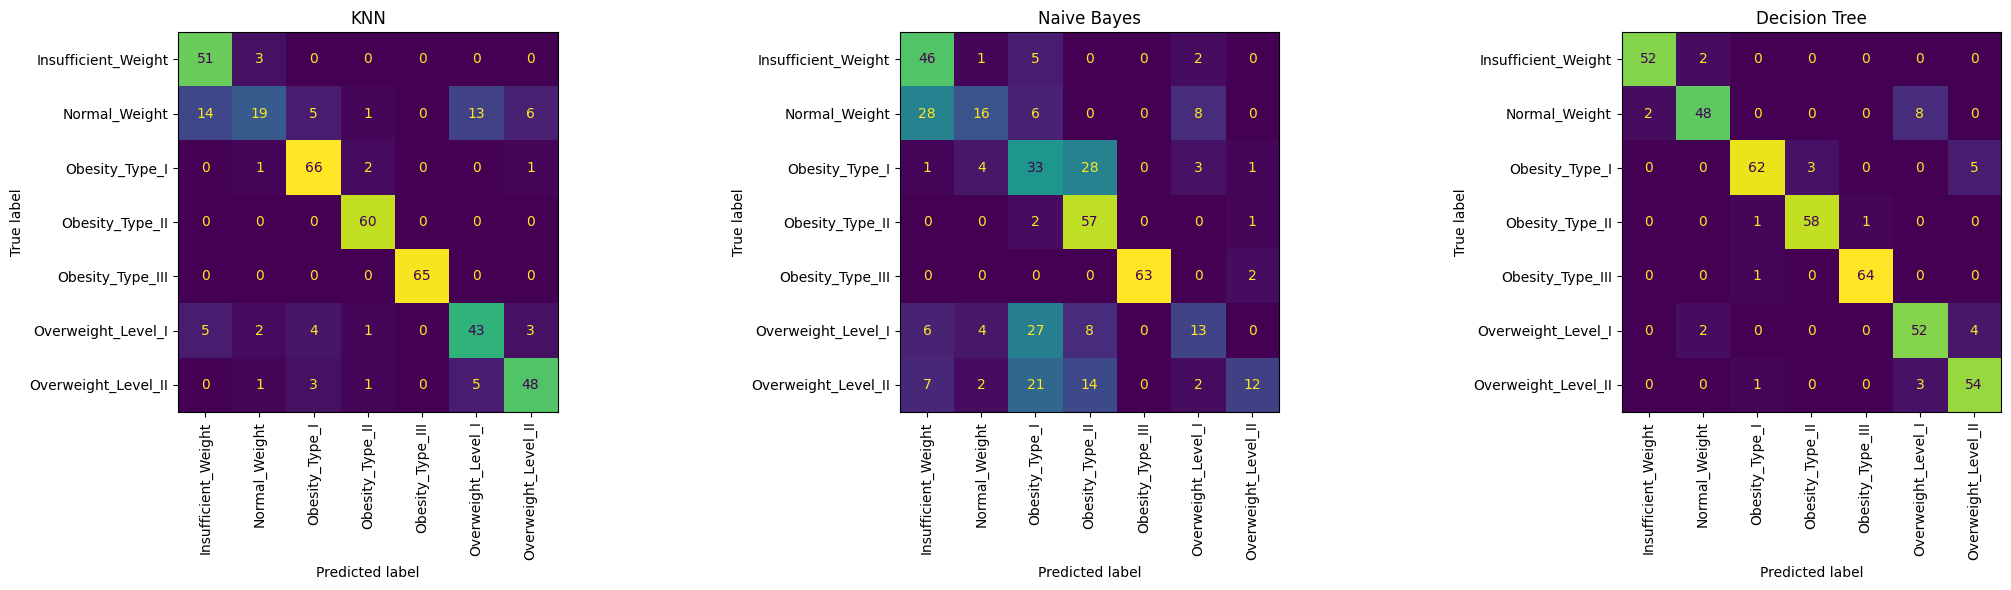

In [27]:
predictions = {
    "KNN": pred_knn,
    "Naive Bayes": pred_naive_bayes,
    "Decision Tree": pred_tree
}

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=90, ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()